# NYC Taxi Machine Learning Project

## Objective

The goal of this project is to use NYC Yellow Taxi trip data to
learn and apply different Machine Learning techniques.

The project covers:

- Regression: Predict total trip amount
- Classification: Predict whether a trip receives a high tip
- Clustering: Group similar taxi trips
- PCA: Reduce dimensionality and visualize trip patterns

The main goal is not only to achieve good model performance,
but also to understand the complete Machine Learning workflow.

In [787]:
import pandas as pd
import numpy as np

In [788]:
df = pd.read_csv("NYC_Taxi_2024.csv")

C:\Users\BharataAshoka\AppData\Local\Temp\ipykernel_29196\2340722147.py:1: DtypeWarning: Columns (0: store_and_fwd_flag) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("NYC_Taxi_2024.csv")


In [789]:
df

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.70,1.00,0.5,0.00,0.00,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.00,3.50,0.5,3.75,0.00,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.30,3.50,0.5,3.00,0.00,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.00,3.50,0.5,2.00,0.00,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.90,3.50,0.5,3.20,0.00,1.0,16.10,2.5,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2964619,2,2024-01-31 23:45:59,2024-01-31 23:54:36,NaN,3.18,NaN,NaN,107,263,0,15.77,0.00,0.5,2.00,0.00,1.0,21.77,NaN,NaN
2964620,1,2024-01-31 23:13:07,2024-01-31 23:27:52,NaN,4.00,NaN,NaN,114,236,0,18.40,1.00,0.5,2.34,0.00,1.0,25.74,NaN,NaN
2964621,2,2024-01-31 23:19:00,2024-01-31 23:38:00,NaN,3.33,NaN,NaN,211,25,0,19.97,0.00,0.5,0.00,0.00,1.0,23.97,NaN,NaN
2964622,2,2024-01-31 23:07:23,2024-01-31 23:25:14,NaN,3.06,NaN,NaN,107,13,0,23.88,0.00,0.5,5.58,0.00,1.0,33.46,NaN,NaN


In [790]:
df.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'Airport_fee'],
      dtype='str')

In [791]:
df.shape

(2964624, 19)

In [792]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2964624 entries, 0 to 2964623
Data columns (total 19 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   VendorID               int64  
 1   tpep_pickup_datetime   str    
 2   tpep_dropoff_datetime  str    
 3   passenger_count        float64
 4   trip_distance          float64
 5   RatecodeID             float64
 6   store_and_fwd_flag     str    
 7   PULocationID           int64  
 8   DOLocationID           int64  
 9   payment_type           int64  
 10  fare_amount            float64
 11  extra                  float64
 12  mta_tax                float64
 13  tip_amount             float64
 14  tolls_amount           float64
 15  improvement_surcharge  float64
 16  total_amount           float64
 17  congestion_surcharge   float64
 18  Airport_fee            float64
dtypes: float64(12), int64(4), str(3)
memory usage: 540.2 MB


In [793]:
df.describe()

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
count,2.964624e+06,2.824462e+06,2.964624e+06,2.824462e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.824462e+06,2.824462e+06
mean,1.754204e+00,1.339281e+00,3.652169e+00,2.069359e+00,1.660179e+02,1.651167e+02,1.161271e+00,1.817506e+01,1.451598e+00,4.833823e-01,3.335870e+00,5.270212e-01,9.756319e-01,2.680150e+01,2.256122e+00,1.411611e-01
std,4.325902e-01,8.502817e-01,2.254626e+02,9.823219e+00,6.362391e+01,6.931535e+01,5.808686e-01,1.894955e+01,1.804102e+00,1.177600e-01,3.896551e+00,2.128310e+00,2.183645e-01,2.338558e+01,8.232747e-01,4.876239e-01
min,1.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,-8.990000e+02,-7.500000e+00,-5.000000e-01,-8.000000e+01,-8.000000e+01,-1.000000e+00,-9.000000e+02,-2.500000e+00,-1.750000e+00
25%,2.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.320000e+02,1.140000e+02,1.000000e+00,8.600000e+00,0.000000e+00,5.000000e-01,1.000000e+00,0.000000e+00,1.000000e+00,1.538000e+01,2.500000e+00,0.000000e+00
50%,2.000000e+00,1.000000e+00,1.680000e+00,1.000000e+00,1.620000e+02,1.620000e+02,1.000000e+00,1.280000e+01,1.000000e+00,5.000000e-01,2.700000e+00,0.000000e+00,1.000000e+00,2.010000e+01,2.500000e+00,0.000000e+00
75%,2.000000e+00,1.000000e+00,3.110000e+00,1.000000e+00,2.340000e+02,2.340000e+02,1.000000e+00,2.050000e+01,2.500000e+00,5.000000e-01,4.120000e+00,0.000000e+00,1.000000e+00,2.856000e+01,2.500000e+00,0.000000e+00
max,6.000000e+00,9.000000e+00,3.127223e+05,9.900000e+01,2.650000e+02,2.650000e+02,4.000000e+00,5.000000e+03,1.425000e+01,4.000000e+00,4.280000e+02,1.159200e+02,1.000000e+00,5.000000e+03,2.500000e+00,1.750000e+00


In [794]:
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

In [795]:
df.isnull().sum()

VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          140162
trip_distance                 0
RatecodeID               140162
store_and_fwd_flag       140162
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   0
extra                         0
mta_tax                       0
tip_amount                    0
tolls_amount                  0
improvement_surcharge         0
total_amount                  0
congestion_surcharge     140162
Airport_fee              140162
dtype: int64

In [796]:
missing_percentage = df.isnull().mean() * 100

missing_percentage

VendorID                 0.000000
tpep_pickup_datetime     0.000000
tpep_dropoff_datetime    0.000000
passenger_count          4.727817
trip_distance            0.000000
RatecodeID               4.727817
store_and_fwd_flag       4.727817
PULocationID             0.000000
DOLocationID             0.000000
payment_type             0.000000
fare_amount              0.000000
extra                    0.000000
mta_tax                  0.000000
tip_amount               0.000000
tolls_amount             0.000000
improvement_surcharge    0.000000
total_amount             0.000000
congestion_surcharge     4.727817
Airport_fee              4.727817
dtype: float64

In [797]:
df.duplicated().sum()

np.int64(0)

In [798]:
df.head(10)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.00
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.00
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.00
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.00
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.00
5,1,2024-01-01 00:54:08,2024-01-01 01:26:31,1.0,4.70,1.0,N,148,141,1,29.6,3.5,0.5,6.90,0.0,1.0,41.50,2.5,0.00
6,2,2024-01-01 00:49:44,2024-01-01 01:15:47,2.0,10.82,1.0,N,138,181,1,45.7,6.0,0.5,10.00,0.0,1.0,64.95,0.0,1.75
7,1,2024-01-01 00:30:40,2024-01-01 00:58:40,0.0,3.00,1.0,N,246,231,2,25.4,3.5,0.5,0.00,0.0,1.0,30.40,2.5,0.00
8,2,2024-01-01 00:26:01,2024-01-01 00:54:12,1.0,5.44,1.0,N,161,261,2,31.0,1.0,0.5,0.00,0.0,1.0,36.00,2.5,0.00
9,2,2024-01-01 00:28:08,2024-01-01 00:29:16,1.0,0.04,1.0,N,113,113,2,3.0,1.0,0.5,0.00,0.0,1.0,8.00,2.5,0.00


In [799]:
df[df['passenger_count'].isnull()].head(10)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
2824462,2,2024-01-01 00:34:19,2024-01-01 00:51:22,NaN,2.04,NaN,NaN,143,141,0,12.72,0.0,0.5,0.00,0.0,1.0,16.72,NaN,NaN
2824463,1,2024-01-01 00:14:31,2024-01-01 00:19:29,NaN,1.60,NaN,NaN,236,238,0,9.30,1.0,0.5,2.86,0.0,1.0,17.16,NaN,NaN
2824464,1,2024-01-01 00:35:11,2024-01-01 01:13:40,NaN,0.00,NaN,NaN,142,79,0,21.01,0.0,0.5,0.00,0.0,1.0,25.01,NaN,NaN
2824465,1,2024-01-01 00:33:37,2024-01-01 00:50:34,NaN,0.00,NaN,NaN,237,4,0,17.79,0.0,0.5,0.00,0.0,1.0,21.79,NaN,NaN
2824466,1,2024-01-01 00:49:04,2024-01-01 01:01:16,NaN,0.00,NaN,NaN,244,50,0,34.65,0.0,0.5,0.00,0.0,1.0,38.65,NaN,NaN
2824467,2,2024-01-01 00:47:00,2024-01-01 01:11:05,NaN,4.58,NaN,NaN,202,83,0,28.14,0.0,0.5,0.00,0.0,1.0,29.64,NaN,NaN
2824468,2,2024-01-01 00:48:10,2024-01-01 01:00:24,NaN,1.47,NaN,NaN,224,144,0,12.82,0.0,0.5,0.00,0.0,1.0,16.82,NaN,NaN
2824469,1,2024-01-01 00:53:57,2024-01-01 01:09:58,NaN,1.70,NaN,NaN,79,249,0,10.16,0.0,0.5,0.00,0.0,1.0,11.66,NaN,NaN
2824470,2,2024-01-01 00:55:27,2024-01-01 01:38:45,NaN,4.80,NaN,NaN,158,239,0,33.12,0.0,0.5,7.42,0.0,1.0,44.54,NaN,NaN
2824471,2,2024-01-01 00:36:00,2024-01-01 00:43:00,NaN,1.27,NaN,NaN,211,90,0,11.74,0.0,0.5,3.15,0.0,1.0,18.89,NaN,NaN


In [800]:
missing_cols = [
    "passenger_count",
    "RatecodeID",
    "store_and_fwd_flag",
    "congestion_surcharge",
    "Airport_fee"
]

df[missing_cols].isnull().all(axis=1).sum()

np.int64(140162)

In [801]:
df[missing_cols].isnull().all(axis=1).sum()

np.int64(140162)

In [802]:
df[df["passenger_count"].isnull()].head(10)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
2824462,2,2024-01-01 00:34:19,2024-01-01 00:51:22,NaN,2.04,NaN,NaN,143,141,0,12.72,0.0,0.5,0.00,0.0,1.0,16.72,NaN,NaN
2824463,1,2024-01-01 00:14:31,2024-01-01 00:19:29,NaN,1.60,NaN,NaN,236,238,0,9.30,1.0,0.5,2.86,0.0,1.0,17.16,NaN,NaN
2824464,1,2024-01-01 00:35:11,2024-01-01 01:13:40,NaN,0.00,NaN,NaN,142,79,0,21.01,0.0,0.5,0.00,0.0,1.0,25.01,NaN,NaN
2824465,1,2024-01-01 00:33:37,2024-01-01 00:50:34,NaN,0.00,NaN,NaN,237,4,0,17.79,0.0,0.5,0.00,0.0,1.0,21.79,NaN,NaN
2824466,1,2024-01-01 00:49:04,2024-01-01 01:01:16,NaN,0.00,NaN,NaN,244,50,0,34.65,0.0,0.5,0.00,0.0,1.0,38.65,NaN,NaN
2824467,2,2024-01-01 00:47:00,2024-01-01 01:11:05,NaN,4.58,NaN,NaN,202,83,0,28.14,0.0,0.5,0.00,0.0,1.0,29.64,NaN,NaN
2824468,2,2024-01-01 00:48:10,2024-01-01 01:00:24,NaN,1.47,NaN,NaN,224,144,0,12.82,0.0,0.5,0.00,0.0,1.0,16.82,NaN,NaN
2824469,1,2024-01-01 00:53:57,2024-01-01 01:09:58,NaN,1.70,NaN,NaN,79,249,0,10.16,0.0,0.5,0.00,0.0,1.0,11.66,NaN,NaN
2824470,2,2024-01-01 00:55:27,2024-01-01 01:38:45,NaN,4.80,NaN,NaN,158,239,0,33.12,0.0,0.5,7.42,0.0,1.0,44.54,NaN,NaN
2824471,2,2024-01-01 00:36:00,2024-01-01 00:43:00,NaN,1.27,NaN,NaN,211,90,0,11.74,0.0,0.5,3.15,0.0,1.0,18.89,NaN,NaN


In [803]:
df[df["passenger_count"].isnull()]["VendorID"].value_counts()

VendorID
2    91447
1    48455
6      260
Name: count, dtype: int64

In [804]:
df[df["passenger_count"].isnull()]["payment_type"].value_counts()

payment_type
0    140162
Name: count, dtype: int64

In [805]:
df = df.dropna()

In [806]:
df.isnull().sum()

VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
RatecodeID               0
store_and_fwd_flag       0
PULocationID             0
DOLocationID             0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
congestion_surcharge     0
Airport_fee              0
dtype: int64

In [807]:
df.shape

(2824462, 19)

In [808]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
VendorID,2824462.0,1.758794,1.0,2.0,2.0,2.0,2.0,0.427815
tpep_pickup_datetime,2824462,2024-01-17 01:05:51.479761,2002-12-31 22:59:39,2024-01-09 15:31:44,2024-01-17 10:36:41,2024-01-24 18:44:19,2024-02-01 00:01:15,NaN
tpep_dropoff_datetime,2824462,2024-01-17 01:21:27.433029,2002-12-31 23:05:41,2024-01-09 15:48:48.250000,2024-01-17 10:55:22,2024-01-24 18:59:22,2024-02-02 13:56:52,NaN
passenger_count,2824462.0,1.339281,0.0,1.0,1.0,1.0,9.0,0.850282
trip_distance,2824462.0,3.254071,0.0,1.0,1.67,3.1,15400.32,12.132039
RatecodeID,2824462.0,2.069359,1.0,1.0,1.0,1.0,99.0,9.823219
PULocationID,2824462.0,166.221804,1.0,132.0,162.0,234.0,265.0,63.195533
DOLocationID,2824462.0,165.487657,1.0,114.0,162.0,234.0,265.0,69.199253
payment_type,2824462.0,1.218898,1.0,1.0,1.0,1.0,4.0,0.532832
fare_amount,2824462.0,18.083697,-899.0,8.6,12.8,19.8,5000.0,19.19273


In [809]:
df = df[
    (df["tpep_pickup_datetime"] >= "2024-01-01") &
    (df["tpep_pickup_datetime"] < "2024-02-01")
]

In [810]:
df = df[
    (df["tpep_dropoff_datetime"] >= "2024-01-01") &
    (df["tpep_dropoff_datetime"] < "2024-02-01")
]

In [811]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
VendorID,2823852.0,1.758779,1.0,2.0,2.0,2.0,2.0,0.427824
tpep_pickup_datetime,2823852,2024-01-17 01:17:39.507181,2024-01-01 00:00:00,2024-01-09 15:30:23.750000,2024-01-17 10:33:26.500000,2024-01-24 18:40:53.250000,2024-01-31 23:59:29,NaN
tpep_dropoff_datetime,2823852,2024-01-17 01:33:13.694516,2024-01-01 00:02:42,2024-01-09 15:47:31,2024-01-17 10:52:29,2024-01-24 18:56:20.250000,2024-01-31 23:59:59,NaN
passenger_count,2823852.0,1.339292,0.0,1.0,1.0,1.0,9.0,0.850293
trip_distance,2823852.0,3.253215,0.0,1.0,1.67,3.1,15400.32,12.132701
RatecodeID,2823852.0,2.069552,1.0,1.0,1.0,1.0,99.0,9.824268
PULocationID,2823852.0,166.225795,1.0,132.0,162.0,234.0,265.0,63.196242
DOLocationID,2823852.0,165.490373,1.0,114.0,162.0,234.0,265.0,69.19727
payment_type,2823852.0,1.218906,1.0,1.0,1.0,1.0,4.0,0.532842
fare_amount,2823852.0,18.080633,-899.0,8.6,12.8,19.8,5000.0,19.189109


In [812]:
df.shape

(2823852, 19)

In [813]:
df = df[
    (df["trip_distance"] > 0) &
    (df["total_amount"] > 0) &
    (df["fare_amount"] > 0) &
    (df["tolls_amount"] > 0)
]

In [814]:
df = df[
    (df["trip_distance"] > 0) &
    (df["total_amount"] > 0) &
    (df["fare_amount"] > 0) &
    (df["tolls_amount"] >= 0)
]

In [815]:
df.shape

(199581, 19)

In [816]:
df["trip_distance"].quantile([0.90, 0.95, 0.99, 0.999])

0.900    20.0000
0.950    21.4600
0.990    30.0600
0.999    53.8956
Name: trip_distance, dtype: float64

In [817]:
df["fare_amount"].quantile([0.90, 0.95, 0.99, 0.999])

0.900     70.000
0.950     85.600
0.990    136.700
0.999    282.594
Name: fare_amount, dtype: float64

In [818]:
df["total_amount"].quantile([0.90, 0.95, 0.99, 0.999])

0.900    103.6800
0.950    113.2300
0.990    174.6900
0.999    333.1888
Name: total_amount, dtype: float64

In [819]:
df["trip_duration_minutes"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

In [820]:
df["trip_duration_minutes"].describe()

count    199581.000000
mean         36.735351
std          34.769907
min          -6.066667
25%          24.650000
50%          33.350000
75%          44.633333
max        3621.766667
Name: trip_duration_minutes, dtype: float64

In [821]:
df[["trip_distance", "fare_amount", "total_amount", "tolls_amount"]].describe()

,trip_distance,fare_amount,total_amount,tolls_amount
count,199581.000000,199581.000000,199581.000000,199581.000000
mean,14.033450,57.650171,83.092817,7.550005
std,25.331052,24.237897,27.365800,3.047118
min,0.010000,0.010000,7.950000,0.010000
25%,9.400000,40.800000,66.790000,6.940000
50%,12.830000,57.600000,82.010000,6.940000
75%,18.000000,70.000000,97.690000,6.940000
max,10879.280000,912.300000,940.930000,115.920000


In [822]:
df.nlargest(10, "trip_distance")[
    [
        "trip_distance",
        "fare_amount",
        "total_amount",
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime"
    ]
]

,trip_distance,fare_amount,total_amount,tpep_pickup_datetime,tpep_dropoff_datetime
166339,10879.28,70.0,98.88,2024-01-03 11:02:57,2024-01-03 11:47:35
1201773,1715.22,70.0,98.88,2024-01-14 17:22:52,2024-01-14 18:05:15
960355,210.82,500.0,515.88,2024-01-12 10:40:28,2024-01-12 13:46:56
1372494,210.20,650.0,689.68,2024-01-16 19:00:33,2024-01-16 23:07:48
2049647,155.56,450.0,494.38,2024-01-24 04:31:22,2024-01-24 06:52:18
2287933,153.20,550.4,573.97,2024-01-26 12:49:27,2024-01-26 16:01:22
507314,142.62,912.3,940.93,2024-01-06 21:01:38,2024-01-06 23:41:44
1307402,135.82,220.0,281.83,2024-01-16 07:37:46,2024-01-16 09:34:19
1188153,122.47,749.2,758.89,2024-01-14 15:49:26,2024-01-14 18:00:27
1109079,120.86,457.0,473.38,2024-01-13 17:57:22,2024-01-13 20:27:50


In [823]:
df.nlargest(10, "fare_amount")[
    [
        "trip_distance",
        "fare_amount",
        "total_amount"
    ]
]

,trip_distance,fare_amount,total_amount
507314,142.62,912.3,940.93
1413328,109.75,761.1,775.48
1188153,122.47,749.2,758.89
2354217,120.76,744.3,753.74
2522757,119.46,739.4,771.41
541146,0.11,700.0,715.75
571382,111.57,678.5,696.00
1850352,110.46,669.4,709.21
1372494,210.20,650.0,689.68
2139108,94.47,637.9,648.59


In [824]:
df["trip_duration_minutes"] = (
    df["tpep_dropoff_datetime"] -
    df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

In [825]:
df["trip_duration_minutes"].describe()

count    199581.000000
mean         36.735351
std          34.769907
min          -6.066667
25%          24.650000
50%          33.350000
75%          44.633333
max        3621.766667
Name: trip_duration_minutes, dtype: float64

In [826]:
df["trip_duration_minutes"].quantile(
    [0.90, 0.95, 0.99, 0.999, 0.9999]
)

0.9000      56.400000
0.9500      64.216667
0.9900      84.466667
0.9990     185.117333
0.9999    1423.098000
Name: trip_duration_minutes, dtype: float64

In [827]:
df = df[df["trip_duration_minutes"] > 0]

In [828]:
df["trip_duration_minutes"].describe()

count    199578.000000
mean         36.735934
std          34.769842
min           0.033333
25%          24.650000
50%          33.350000
75%          44.633333
max        3621.766667
Name: trip_duration_minutes, dtype: float64

In [829]:
df = df[
    (df["trip_duration_minutes"] > 0) &
    (df["trip_duration_minutes"] <= 120)
]

In [830]:
df.shape

(199137, 20)

In [831]:
df["trip_distance"].quantile(
    [0.90, 0.95, 0.99, 0.999, 0.9999]
)

0.9000    19.990000
0.9500    21.440000
0.9900    29.930000
0.9990    52.752320
0.9999    82.794432
Name: trip_distance, dtype: float64

In [832]:
df["trip_distance"].describe()

count    199137.000000
mean         14.011524
std          25.325588
min           0.010000
25%           9.400000
50%          12.800000
75%          18.000000
max       10879.280000
Name: trip_distance, dtype: float64

In [833]:
df.nlargest(15, "trip_distance")[
    [
        "trip_distance",
        "trip_duration_minutes",
        "fare_amount",
        "total_amount"
    ]
]

,trip_distance,trip_duration_minutes,fare_amount,total_amount
166339,10879.28,44.633333,70.0,98.88
1201773,1715.22,42.383333,70.0,98.88
1307402,135.82,116.550000,220.0,281.83
770905,115.75,111.766667,400.0,409.69
571382,111.57,114.383333,678.5,696.00
1187539,108.60,118.933333,380.0,420.00
2407013,99.00,105.466667,591.7,623.71
1390222,97.22,99.216667,586.1,610.67
2815982,94.52,92.150000,595.2,606.39
2139108,94.47,113.400000,637.9,648.59


In [834]:
df["average_speed_mph"] = (
    df["trip_distance"] /
    (df["trip_duration_minutes"] / 60)
)

In [835]:
df["average_speed_mph"].describe()

count    199137.000000
mean         25.586429
std         107.924188
min           0.010190
25%          18.954745
50%          23.907157
75%          29.884170
max       35316.000000
Name: average_speed_mph, dtype: float64

In [836]:
df["average_speed_mph"].quantile(
    [0.90, 0.95, 0.99, 0.999, 0.9999]
)

0.9000      35.357143
0.9500      38.604312
0.9900      44.790821
0.9990      53.164197
0.9999    2306.504383
Name: average_speed_mph, dtype: float64

In [837]:
df.nlargest(15, "average_speed_mph")[
    [
        "trip_distance",
        "trip_duration_minutes",
        "average_speed_mph",
        "fare_amount",
        "total_amount"
    ]
]

,trip_distance,trip_duration_minutes,average_speed_mph,fare_amount,total_amount
522697,19.62,0.033333,35316.000000,70.0,80.19
1968838,9.30,0.033333,16740.000000,37.3,59.94
166339,10879.28,44.633333,14624.872293,70.0,98.88
2724568,32.90,0.150000,13160.000000,70.0,80.94
1487123,17.00,0.133333,7650.000000,70.0,97.09
2593461,22.80,0.200000,6840.000000,70.0,95.19
1462191,6.50,0.066667,5850.000000,70.0,100.09
2628570,17.60,0.183333,5760.000000,70.0,97.09
1482043,17.00,0.183333,5563.636364,70.0,97.09
2191438,17.00,0.183333,5563.636364,70.0,90.00


In [838]:
df["average_speed_mph"] = (
    df["trip_distance"] /
    (df["trip_duration_minutes"] / 60)
)

In [839]:
df["average_speed_mph"].quantile(
    [0.90, 0.95, 0.99, 0.999, 0.9999]
)

0.9000      35.357143
0.9500      38.604312
0.9900      44.790821
0.9990      53.164197
0.9999    2306.504383
Name: average_speed_mph, dtype: float64

In [840]:
df.nlargest(15, "average_speed_mph")[
    ["trip_distance", "trip_duration_minutes", "average_speed_mph"]
]

,trip_distance,trip_duration_minutes,average_speed_mph
522697,19.62,0.033333,35316.000000
1968838,9.30,0.033333,16740.000000
166339,10879.28,44.633333,14624.872293
2724568,32.90,0.150000,13160.000000
1487123,17.00,0.133333,7650.000000
2593461,22.80,0.200000,6840.000000
1462191,6.50,0.066667,5850.000000
2628570,17.60,0.183333,5760.000000
1482043,17.00,0.183333,5563.636364
2191438,17.00,0.183333,5563.636364


In [841]:
before = len(df)

df = df[
    (df["average_speed_mph"] > 0) &
    (df["average_speed_mph"] <= 80)
]

after = len(df)

print("Rows before:", before)
print("Rows after:", after)
print("Rows removed:", before - after)
print("Percentage removed:", (before - after) / before * 100)

Rows before: 199137
Rows after: 199068
Rows removed: 69
Percentage removed: 0.03464951264707212


In [842]:
df["average_speed_mph"].describe()

count    199068.000000
mean         24.643450
std           7.921335
min           0.010190
25%          18.952949
50%          23.904052
75%          29.877844
max          76.836790
Name: average_speed_mph, dtype: float64

In [843]:
df["trip_distance"].describe()

count    199068.000000
mean         13.947406
std           5.827103
min           0.010000
25%           9.400000
50%          12.800000
75%          18.000000
max         135.820000
Name: trip_distance, dtype: float64

In [844]:
df = df[df["trip_duration_minutes"] >= 1]

In [845]:
df.shape

(198602, 21)

In [846]:
df["pickup_hour"] = df["tpep_pickup_datetime"].dt.hour

In [847]:
df["pickup_hour"]

12          0
24          0
32          0
55          0
62          0
           ..
2824359    23
2824387    23
2824394    23
2824402    23
2824432    23
Name: pickup_hour, Length: 198602, dtype: int32

In [848]:
df["pickup_dayofweek"] = df["tpep_pickup_datetime"].dt.dayofweek

In [849]:
df["pickup_dayofweek"]

12         0
24         0
32         0
55         0
62         0
          ..
2824359    2
2824387    2
2824394    2
2824402    2
2824432    2
Name: pickup_dayofweek, Length: 198602, dtype: int32

In [850]:
df["is_weekend"] = (df["pickup_dayofweek"] >= 5).astype(int)

In [851]:
df["is_weekend"].dtype

dtype('int64')

In [852]:
df

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,trip_duration_minutes,average_speed_mph,pickup_hour,pickup_dayofweek,is_weekend
12,1,2024-01-01 00:35:16,2024-01-01 01:11:52,2.0,8.20,1.0,N,246,190,1,...,6.94,1.0,85.09,2.5,0.00,36.600000,13.442623,0,0,0
24,1,2024-01-01 00:42:05,2024-01-01 01:16:49,1.0,23.90,5.0,N,263,265,1,...,6.94,1.0,127.94,0.0,0.00,34.733333,41.285988,0,0,0
32,2,2024-01-01 00:15:26,2024-01-01 00:33:57,1.0,11.51,1.0,N,262,171,1,...,6.94,1.0,67.49,2.5,0.00,18.516667,37.296130,0,0,0
55,2,2024-01-01 00:13:52,2024-01-01 00:29:41,1.0,8.89,1.0,N,138,107,1,...,6.94,1.0,64.32,2.5,1.75,15.816667,33.723920,0,0,0
62,1,2024-01-01 00:47:51,2024-01-01 01:21:04,1.0,3.80,1.0,N,246,145,1,...,6.94,1.0,47.34,2.5,0.00,33.216667,6.864024,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2824359,2,2024-01-31 23:03:54,2024-01-31 23:45:47,1.0,18.17,2.0,N,132,43,1,...,6.94,1.0,97.69,2.5,1.75,41.883333,26.029447,23,2,0
2824387,2,2024-01-31 23:05:28,2024-01-31 23:27:51,1.0,9.16,1.0,N,138,186,1,...,6.94,1.0,63.39,2.5,1.75,22.383333,24.553984,23,2,0
2824394,2,2024-01-31 23:25:29,2024-01-31 23:50:20,1.0,10.11,1.0,N,138,239,1,...,6.94,1.0,66.89,2.5,1.75,24.850000,24.410463,23,2,0
2824402,2,2024-01-31 23:00:26,2024-01-31 23:25:06,2.0,4.32,1.0,N,114,142,1,...,5.20,1.0,34.90,2.5,0.00,24.666667,10.508108,23,2,0


In [853]:
df[df["is_weekend"] == True]

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,trip_duration_minutes,average_speed_mph,pickup_hour,pickup_dayofweek,is_weekend
420667,2,2024-01-06 00:07:50,2024-01-06 00:32:17,1.0,9.07,1.0,N,138,238,1,...,6.94,1.0,66.80,2.5,1.75,24.450000,22.257669,0,5,1
424782,2,2024-01-06 00:15:37,2024-01-06 00:48:23,1.0,17.37,2.0,N,132,229,2,...,6.94,1.0,80.94,2.5,0.00,32.766667,31.806714,0,5,1
424857,2,2024-01-06 00:04:49,2024-01-06 00:26:06,1.0,5.05,1.0,N,234,255,1,...,6.94,1.0,41.84,2.5,0.00,21.283333,14.236492,0,5,1
424883,2,2024-01-06 00:08:50,2024-01-06 00:43:17,2.0,18.89,2.0,N,132,263,1,...,6.94,1.0,99.23,2.5,1.75,34.450000,32.899855,0,5,1
424890,2,2024-01-06 00:21:46,2024-01-06 01:10:52,4.0,38.19,4.0,N,132,265,1,...,6.94,1.0,205.49,0.0,1.75,49.100000,46.668024,0,5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2545812,2,2024-01-28 23:39:49,2024-01-29 00:08:52,2.0,20.25,1.0,N,132,169,2,...,6.94,1.0,85.59,0.0,1.75,29.050000,41.824441,23,6,1
2545825,2,2024-01-28 23:46:14,2024-01-29 00:11:29,1.0,13.00,1.0,N,138,87,1,...,6.94,1.0,81.12,2.5,1.75,25.250000,30.891089,23,6,1
2545827,2,2024-01-28 23:16:23,2024-01-28 23:37:13,1.0,13.00,1.0,N,132,265,1,...,13.38,1.0,66.13,0.0,1.75,20.833333,37.440000,23,6,1
2545829,2,2024-01-28 23:14:46,2024-01-28 23:53:45,1.0,19.13,2.0,N,132,75,2,...,6.94,1.0,80.19,0.0,1.75,38.983333,29.443352,23,6,1


In [854]:
df["pickup_date"] = df["tpep_pickup_datetime"].dt.date

In [855]:
df["pickup_date"]

12         2024-01-01
24         2024-01-01
32         2024-01-01
55         2024-01-01
62         2024-01-01
              ...    
2824359    2024-01-31
2824387    2024-01-31
2824394    2024-01-31
2824402    2024-01-31
2824432    2024-01-31
Name: pickup_date, Length: 198602, dtype: object

In [856]:
df.shape

(198602, 25)

In [857]:
df[
    [
        "trip_distance",
        "trip_duration_minutes",
        "fare_amount",
        "total_amount"
    ]
].corr()

,trip_distance,trip_duration_minutes,fare_amount,total_amount
trip_distance,1.000000,0.618106,0.873504,0.813174
trip_duration_minutes,0.618106,1.000000,0.557560,0.500641
fare_amount,0.873504,0.557560,1.000000,0.949206
total_amount,0.813174,0.500641,0.949206,1.000000


<Axes: >

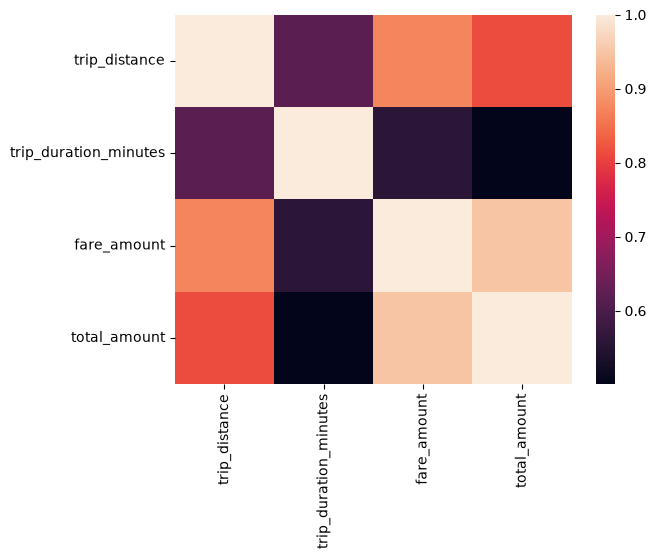

In [858]:
import seaborn as sns
sns.heatmap(df[
    [
        "trip_distance",
        "trip_duration_minutes",
        "fare_amount",
        "total_amount"
    ]
].corr())

In [859]:
df

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,trip_duration_minutes,average_speed_mph,pickup_hour,pickup_dayofweek,is_weekend,pickup_date
12,1,2024-01-01 00:35:16,2024-01-01 01:11:52,2.0,8.20,1.0,N,246,190,1,...,1.0,85.09,2.5,0.00,36.600000,13.442623,0,0,0,2024-01-01
24,1,2024-01-01 00:42:05,2024-01-01 01:16:49,1.0,23.90,5.0,N,263,265,1,...,1.0,127.94,0.0,0.00,34.733333,41.285988,0,0,0,2024-01-01
32,2,2024-01-01 00:15:26,2024-01-01 00:33:57,1.0,11.51,1.0,N,262,171,1,...,1.0,67.49,2.5,0.00,18.516667,37.296130,0,0,0,2024-01-01
55,2,2024-01-01 00:13:52,2024-01-01 00:29:41,1.0,8.89,1.0,N,138,107,1,...,1.0,64.32,2.5,1.75,15.816667,33.723920,0,0,0,2024-01-01
62,1,2024-01-01 00:47:51,2024-01-01 01:21:04,1.0,3.80,1.0,N,246,145,1,...,1.0,47.34,2.5,0.00,33.216667,6.864024,0,0,0,2024-01-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2824359,2,2024-01-31 23:03:54,2024-01-31 23:45:47,1.0,18.17,2.0,N,132,43,1,...,1.0,97.69,2.5,1.75,41.883333,26.029447,23,2,0,2024-01-31
2824387,2,2024-01-31 23:05:28,2024-01-31 23:27:51,1.0,9.16,1.0,N,138,186,1,...,1.0,63.39,2.5,1.75,22.383333,24.553984,23,2,0,2024-01-31
2824394,2,2024-01-31 23:25:29,2024-01-31 23:50:20,1.0,10.11,1.0,N,138,239,1,...,1.0,66.89,2.5,1.75,24.850000,24.410463,23,2,0,2024-01-31
2824402,2,2024-01-31 23:00:26,2024-01-31 23:25:06,2.0,4.32,1.0,N,114,142,1,...,1.0,34.90,2.5,0.00,24.666667,10.508108,23,2,0,2024-01-31


In [860]:
features = [
    "trip_distance",
    "trip_duration_minutes",
    "passenger_count",
    "pickup_hour",
    "pickup_dayofweek",
    "is_weekend",
    "PULocationID",
    "DOLocationID"
]

x = df[features]
y = df["total_amount"]

In [861]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [862]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(158881, 8)
(39721, 8)
(158881,)
(39721,)


In [863]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 3.78,-0.02, 0.14,...,-2.34, 0.01,-0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['trip_distance','trip_duration_minutes','passenger_count',..., 'is_weekend','PULocationID','DOLocationID']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,29.71
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,8


In [864]:
y_pred = model.predict(x_test)

In [865]:
comparison = pd.DataFrame({
    "Actual":y_test.values,
    "Predicted":y_pred
})

comparison.head(10)

,Actual,Predicted
0,50.79,59.979687
1,66.00,61.804236
2,65.57,66.409502
3,98.88,106.155797
4,61.25,64.798633
5,84.96,76.524631
6,67.49,75.465635
7,105.89,98.646939
8,108.48,95.845976
9,71.45,65.634456


In [866]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("R²:", r2)

MAE: 9.549303090924946
MSE: 233.9364215599125
R²: 0.6571226212433583


In [867]:
coefficients = pd.DataFrame({
    "Feature": x_train.columns,
    "Coefficient": model.coef_
})

coefficients.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

,Feature,Coefficient
0,trip_distance,3.781056
5,is_weekend,-2.343759
4,pickup_dayofweek,0.211461
2,passenger_count,0.143070
3,pickup_hour,0.034503
1,trip_duration_minutes,-0.019823
6,PULocationID,0.008377
7,DOLocationID,-0.004790


In [868]:
import numpy as np

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("RMSE:", rmse)

RMSE: 15.294980273276344


In [869]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(
    max_depth=12,
    random_state=42)

In [870]:
tree_model.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",12
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes ma

In [871]:
tree_pred = tree_model.predict(x_test)

In [872]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tree_mae = mean_absolute_error(y_test, tree_pred)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_pred))
tree_r2 = r2_score(y_test, tree_pred)

print("Decision Tree MAE:", tree_mae)
print("Decision Tree RMSE:", tree_rmse)
print("Decision Tree R²:", tree_r2)

Decision Tree MAE: 7.046319996085931
Decision Tree RMSE: 12.017524216321352
Decision Tree R²: 0.7883243007465837


In [873]:
print("Linear Regression")
print("MAE:", 3.2719523473681105)
print("RMSE:", np.sqrt(44.20197811892554))
print("R²:", 0.9049619477091729)

print()

print("Decision Tree")
print("MAE:", tree_mae)
print("RMSE:", tree_rmse)
print("R²:", tree_r2)

Linear Regression
MAE: 3.2719523473681105
RMSE: 6.6484568223705525
R²: 0.9049619477091729

Decision Tree
MAE: 7.046319996085931
RMSE: 12.017524216321352
R²: 0.7883243007465837


In [874]:
pd.DataFrame({
    "Actual": y_test.values[:10],
    "Linear": y_pred[:10],
    "DecisionTree": tree_pred[:10]
})

,Actual,Linear,DecisionTree
0,50.79,59.979687,62.733333
1,66.00,61.804236,63.020744
2,65.57,66.409502,65.170304
3,98.88,106.155797,94.075749
4,61.25,64.798633,58.565574
5,84.96,76.524631,82.500075
6,67.49,75.465635,76.353892
7,105.89,98.646939,92.813788
8,108.48,95.845976,98.934640
9,71.45,65.634456,59.989394


In [875]:
train_pred = tree_model.predict(x_train)
test_pred = tree_model.predict(x_test)

train_mae = mean_absolute_error(y_train, train_pred)
test_mae = mean_absolute_error(y_test, test_pred)

train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

print("Training MAE:", train_mae)
print("Testing MAE:", test_mae)

print("Training R²:", train_r2)
print("Testing R²:", test_r2)

Training MAE: 6.274995224338036
Testing MAE: 7.046319996085931
Training R²: 0.8800570617181575
Testing R²: 0.7883243007465837


In [876]:
depths = [3, 5, 8, 12, 16, 20]

for depth in depths:

    model_temp = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    model_temp.fit(x_train, y_train)

    train_pred_temp = model_temp.predict(x_train)
    test_pred_temp = model_temp.predict(x_test)

    print("Depth:", depth)
    print("Train R²:", r2_score(y_train, train_pred_temp))
    print("Test R²:", r2_score(y_test, test_pred_temp))
    print("----------------")

Depth: 3
Train R²: 0.7150904651481831
Test R²: 0.7067648685668074
----------------
Depth: 5
Train R²: 0.8024758468501627
Test R²: 0.7817965841733339
----------------
Depth: 8
Train R²: 0.8350456380077957
Test R²: 0.7903736106560717
----------------
Depth: 12
Train R²: 0.8800570617181575
Test R²: 0.7883243007465837
----------------
Depth: 16
Train R²: 0.9233111491987599
Test R²: 0.7624926917600106
----------------
Depth: 20
Train R²: 0.9533080214761146
Test R²: 0.7371916566643144
----------------


In [877]:
x_rf = x_train.sample(
    n=min(300000, len(x_train)),
    random_state=42
)

y_rf = y_train.loc[x_rf.index]

In [878]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(x_rf, y_rf)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [879]:
rf_pred = rf_model.predict(x_test)

In [880]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("Random Forest MAE:",
      mean_absolute_error(y_test, rf_pred))

print("Random Forest RMSE:",
      np.sqrt(mean_squared_error(y_test, rf_pred)))

print("Random Forest R²:",
      r2_score(y_test, rf_pred))

Random Forest MAE: 6.77021419052657
Random Forest RMSE: 10.985542156979545
Random Forest R²: 0.823117861066505


In [881]:
importance = pd.DataFrame({
    "Feature": x_rf.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance

,Feature,Importance
0,trip_distance,0.819094
7,DOLocationID,0.107469
1,trip_duration_minutes,0.034606
6,PULocationID,0.019679
3,pickup_hour,0.010875
4,pickup_dayofweek,0.003922
2,passenger_count,0.003550
5,is_weekend,0.000806


In [882]:
df.nunique()

VendorID                      2
tpep_pickup_datetime     188884
tpep_dropoff_datetime    189157
passenger_count               9
trip_distance              4206
RatecodeID                    6
store_and_fwd_flag            2
PULocationID                240
DOLocationID                260
payment_type                  4
fare_amount                1118
extra                        23
mta_tax                       3
tip_amount                 3638
tolls_amount                935
improvement_surcharge         3
total_amount              11575
congestion_surcharge          3
Airport_fee                   2
trip_duration_minutes      5906
average_speed_mph        176439
pickup_hour                  24
pickup_dayofweek              7
is_weekend                    2
pickup_date                  31
dtype: int64

In [883]:
sample_df = df.sample(
    n=min(300000, len(df)),
    random_state=42
)

In [884]:
features = [
    "trip_distance",
    "trip_duration_minutes",
    "passenger_count",
    "pickup_hour",
    "pickup_dayofweek",
    "is_weekend",
    "PULocationID",
    "DOLocationID"
]

X_sample = sample_df[features]
y_sample = sample_df["total_amount"]

In [885]:
from sklearn.model_selection import train_test_split

x_train_s, x_test_s, y_train_s, y_test_s = train_test_split(
    X_sample,
    y_sample,
    test_size=0.2,
    random_state=42
)

In [886]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

categorical_cols = [
    "PULocationID",
    "DOLocationID"
]

numeric_cols = [
    "trip_distance",
    "trip_duration_minutes",
    "passenger_count",
    "pickup_hour",
    "pickup_dayofweek",
    "is_weekend"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_cols
        )
    ],
    remainder="passthrough"
)

In [887]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        RandomForestRegressor(
            n_estimators=100,
            max_depth=12,
            random_state=42,
            n_jobs=-1
        )
    )
])

In [888]:
rf_pipeline.fit(
    x_train_s,
    y_train_s
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['trip_distance','trip_duration_minutes','passenger_count',..., 'is_weekend','PULocationID','DOLocationID']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. Th

In [889]:
rf_encoded_pred = rf_pipeline.predict(
    x_test_s
)

In [890]:
print(
    "MAE:",
    mean_absolute_error(
        y_test_s,
        rf_encoded_pred
    )
)

print(
    "RMSE:",
    np.sqrt(
        mean_squared_error(
            y_test_s,
            rf_encoded_pred
        )
    )
)

print(
    "R²:",
    r2_score(
        y_test_s,
        rf_encoded_pred
    )
)

MAE: 6.687500438590723
RMSE: 10.73836263913052
R²: 0.8368907213020722


In [891]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    rf_model,
    x_rf,
    y_rf,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print(scores)
print("Mean R²:", scores.mean())

[0.83777226 0.83102564 0.84179859 0.84244245 0.83052767]
Mean R²: 0.8367133213488988


In [892]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [8, 10, 12, 14, 16],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

In [893]:
search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_grid,
    n_iter=15,
    cv=3,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [894]:
search.fit(x_rf, y_rf)

Fitting 3 folds for each of 15 candidates, totalling 45 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [8, 10, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the s

In [895]:
print("Best parameters:")
print(search.best_params_)

print("Best CV R²:")
print(search.best_score_)

Best parameters:
{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 16}
Best CV R²:
0.840715202104474


In [896]:
error_df = x_test.copy()

In [897]:
error_df["actual"] = y_test.values

In [898]:
error_df["predicted"] = rf_pred

In [899]:
error_df["error"] = (
    error_df["actual"] -
    error_df["predicted"]
)

In [900]:
error_df["absolute_error"] = error_df["error"].abs()

In [901]:
error_df.sort_values(
    "absolute_error",
    ascending=False
).head(20)

,trip_distance,trip_duration_minutes,passenger_count,pickup_hour,pickup_dayofweek,is_weekend,PULocationID,DOLocationID,actual,predicted,error,absolute_error
302089,89.80,89.516667,1.0,19,3,0,155,265,352.73,588.367980,-235.637980,235.637980
658694,45.60,72.283333,3.0,23,0,0,132,265,80.19,294.247544,-214.057544,214.057544
946745,52.09,69.266667,1.0,7,4,0,87,265,107.38,312.856223,-205.476223,205.476223
1684036,70.21,80.883333,1.0,23,4,0,132,265,240.01,432.626248,-192.616248,192.616248
127805,51.24,75.850000,1.0,18,1,0,132,244,87.69,269.882736,-182.192736,182.192736
1391079,51.43,60.300000,1.0,0,2,0,132,220,80.19,257.119827,-176.929827,176.929827
1521058,61.70,104.533333,1.0,11,3,0,132,265,475.79,303.382349,172.407651,172.407651
618005,63.71,84.733333,1.0,14,0,0,138,265,489.60,317.275231,172.324769,172.324769
955208,69.03,74.666667,1.0,9,4,0,246,265,226.38,392.127343,-165.747343,165.747343
1531660,33.25,43.716667,1.0,13,3,0,216,1,362.71,199.829838,162.880162,162.880162


In [902]:
error_df["fare_group"] = pd.cut(
    error_df["actual"],
    bins=[0, 20, 40, 60, 100, 200, float("inf")],
    labels=[
        "0-20",
        "20-40",
        "40-60",
        "60-100",
        "100-200",
        "200+"
    ]
)

In [903]:
error_df.groupby("fare_group")["absolute_error"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
fare_group,,,
0-20,80,22.443724,20.220012
20-40,755,8.587683,6.161600
40-60,4587,7.004986,5.649643
60-100,28696,5.360984,4.091615
100-200,5361,11.853941,8.264858
200+,242,45.953887,33.720906


In [904]:
print(
    "Mean signed error:",
    error_df["error"].mean()
)

Mean signed error: -0.10683472238438106


In [905]:
error_df.groupby(
    "fare_group",
    observed=True
)["absolute_error"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
fare_group,,,
0-20,80,22.443724,20.220012
20-40,755,8.587683,6.161600
40-60,4587,7.004986,5.649643
60-100,28696,5.360984,4.091615
100-200,5361,11.853941,8.264858
200+,242,45.953887,33.720906


In [906]:
error_df["error"].mean()

np.float64(-0.10683472238438106)

In [907]:
error_df.sort_values(
    "absolute_error",
    ascending=False
)[
    [
        "trip_distance",
        "trip_duration_minutes",
        "passenger_count",
        "pickup_hour",
        "PULocationID",
        "DOLocationID",
        "actual",
        "predicted",
        "error",
        "absolute_error"
    ]
].head(20)

,trip_distance,trip_duration_minutes,passenger_count,pickup_hour,PULocationID,DOLocationID,actual,predicted,error,absolute_error
302089,89.80,89.516667,1.0,19,155,265,352.73,588.367980,-235.637980,235.637980
658694,45.60,72.283333,3.0,23,132,265,80.19,294.247544,-214.057544,214.057544
946745,52.09,69.266667,1.0,7,87,265,107.38,312.856223,-205.476223,205.476223
1684036,70.21,80.883333,1.0,23,132,265,240.01,432.626248,-192.616248,192.616248
127805,51.24,75.850000,1.0,18,132,244,87.69,269.882736,-182.192736,182.192736
1391079,51.43,60.300000,1.0,0,132,220,80.19,257.119827,-176.929827,176.929827
1521058,61.70,104.533333,1.0,11,132,265,475.79,303.382349,172.407651,172.407651
618005,63.71,84.733333,1.0,14,138,265,489.60,317.275231,172.324769,172.324769
955208,69.03,74.666667,1.0,9,246,265,226.38,392.127343,-165.747343,165.747343
1531660,33.25,43.716667,1.0,13,216,1,362.71,199.829838,162.880162,162.880162


In [908]:
error_df

,trip_distance,trip_duration_minutes,passenger_count,pickup_hour,pickup_dayofweek,is_weekend,PULocationID,DOLocationID,actual,predicted,error,absolute_error,fare_group
802888,7.60,33.150000,1.0,17,2,0,138,24,50.79,61.184361,-10.394361,10.394361,40-60
512250,8.85,21.800000,1.0,22,5,1,70,237,66.00,63.705707,2.294293,2.294293,60-100
1174711,9.59,20.550000,1.0,13,6,1,238,138,65.57,64.390049,1.179951,1.179951,60-100
2547355,20.31,25.100000,1.0,1,0,0,132,236,98.88,94.589205,4.290795,4.290795,60-100
550167,9.37,27.050000,1.0,14,6,1,186,190,61.25,59.370810,1.879190,1.879190,60-100
...,...,...,...,...,...,...,...,...,...,...,...,...,...
318161,9.61,17.033333,1.0,22,3,0,138,141,66.84,65.691822,1.148178,1.148178,60-100
2576579,9.97,27.983333,1.0,13,0,0,142,138,72.29,69.159562,3.130438,3.130438,60-100
1342511,21.57,55.966667,2.0,14,1,0,132,88,87.69,94.969843,-7.279843,7.279843,60-100
1515314,10.21,45.983333,1.0,10,3,0,138,233,66.89,80.061182,-13.171182,13.171182,60-100


In [909]:
error_df["RatecodeID"] = df.loc[
    error_df.index, "RatecodeID"
]

error_df["payment_type"] = df.loc[
    error_df.index, "payment_type"
]

error_df["Airport_fee"] = df.loc[
    error_df.index, "Airport_fee"
]

error_df["tolls_amount"] = df.loc[
    error_df.index, "tolls_amount"
]

In [910]:
error_df.sort_values(
    "absolute_error",
    ascending=False
)[
    [
        "trip_distance",
        "trip_duration_minutes",
        "pickup_hour",
        "PULocationID",
        "DOLocationID",
        "RatecodeID",
        "payment_type",
        "Airport_fee",
        "tolls_amount",
        "actual",
        "predicted",
        "absolute_error"
    ]
].head(20)

,trip_distance,trip_duration_minutes,pickup_hour,PULocationID,DOLocationID,RatecodeID,payment_type,Airport_fee,tolls_amount,actual,predicted,absolute_error
302089,89.80,89.516667,19,155,265,1.0,2,0.00,28.63,352.73,588.367980,235.637980
658694,45.60,72.283333,23,132,265,2.0,2,1.75,6.94,80.19,294.247544,214.057544
946745,52.09,69.266667,7,87,265,5.0,2,0.00,15.38,107.38,312.856223,205.476223
1684036,70.21,80.883333,23,132,265,5.0,1,1.75,27.26,240.01,432.626248,192.616248
127805,51.24,75.850000,18,132,244,2.0,2,1.75,6.94,87.69,269.882736,182.192736
1391079,51.43,60.300000,0,132,220,2.0,2,1.75,6.94,80.19,257.119827,176.929827
1521058,61.70,104.533333,11,132,265,4.0,1,1.75,26.63,475.79,303.382349,172.407651
618005,63.71,84.733333,14,138,265,4.0,1,1.75,6.94,489.60,317.275231,172.324769
955208,69.03,74.666667,9,246,265,5.0,1,0.00,15.38,226.38,392.127343,165.747343
1531660,33.25,43.716667,13,216,1,5.0,1,0.00,27.26,362.71,199.829838,162.880162


In [911]:
hour_errors = error_df.groupby(
    "pickup_hour"
)["absolute_error"].agg(
    ["count", "mean", "median"]
)

hour_errors

,count,mean,median
pickup_hour,,,
0,883,7.474376,4.603567
1,319,9.524104,5.323575
2,162,11.832352,6.354157
3,207,9.644717,6.265933
4,306,8.676411,5.417537
5,559,7.944600,5.098809
6,902,7.037491,5.002908
7,1231,7.460404,5.016331
8,1324,6.952860,4.989490


In [912]:
rate_errors = error_df.groupby(
    "RatecodeID"
)["absolute_error"].agg(
    ["count", "mean", "median"]
)

rate_errors

,count,mean,median
RatecodeID,,,
1.0,21428,5.085363,3.449846
2.0,15305,6.962141,5.323575
3.0,1266,11.017851,9.251560
4.0,488,24.346307,17.066829
5.0,509,30.273793,22.456225
99.0,725,16.766902,16.275352


In [913]:
hour_errors

,count,mean,median
pickup_hour,,,
0,883,7.474376,4.603567
1,319,9.524104,5.323575
2,162,11.832352,6.354157
3,207,9.644717,6.265933
4,306,8.676411,5.417537
5,559,7.944600,5.098809
6,902,7.037491,5.002908
7,1231,7.460404,5.016331
8,1324,6.952860,4.989490


In [914]:
rate_errors

,count,mean,median
RatecodeID,,,
1.0,21428,5.085363,3.449846
2.0,15305,6.962141,5.323575
3.0,1266,11.017851,9.251560
4.0,488,24.346307,17.066829
5.0,509,30.273793,22.456225
99.0,725,16.766902,16.275352


In [915]:
features = [
    "trip_distance",
    "trip_duration_minutes",
    "passenger_count",
    "pickup_hour",
    "pickup_dayofweek",
    "is_weekend",
    "PULocationID",
    "DOLocationID",
    "RatecodeID"
]

In [916]:
X = df[features]
y = df["total_amount"]

In [917]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [918]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [919]:
rf_pred = rf_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R²:", r2_score(y_test, rf_pred))

MAE: 5.857729173342012
RMSE: 8.732396635154988
R²: 0.8882344657402886


In [920]:
error_df = X_test.copy()

error_df["actual"] = y_test.values
error_df["predicted"] = rf_pred

error_df["error"] = (
    error_df["actual"] -
    error_df["predicted"]
)

error_df["absolute_error"] = (
    error_df["error"].abs()
)

In [921]:
error_df["fare_group"] = pd.cut(
    error_df["actual"],
    bins=[0, 20, 40, 60, 100, 200, float("inf")],
    labels=[
        "0-20",
        "20-40",
        "40-60",
        "60-100",
        "100-200",
        "200+"
    ]
)

error_df.groupby(
    "fare_group",
    observed=True
)["absolute_error"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
fare_group,,,
0-20,80,2.719439,1.933015
20-40,755,3.749839,2.796568
40-60,4587,5.368585,4.366699
60-100,28696,4.996701,4.072945
100-200,5361,9.876675,8.051508
200+,242,35.811130,26.507298


In [922]:
error_df.groupby(
    "RatecodeID"
)["absolute_error"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
RatecodeID,,,
1.0,21428,4.551460,3.372280
2.0,15305,6.370449,5.276723
3.0,1266,10.154460,9.223690
4.0,488,18.719219,13.162998
5.0,509,24.253460,15.224030
99.0,725,4.566780,2.824903


In [923]:
error_df

,trip_distance,trip_duration_minutes,passenger_count,pickup_hour,pickup_dayofweek,is_weekend,PULocationID,DOLocationID,RatecodeID,actual,predicted,error,absolute_error,fare_group
802888,7.60,33.150000,1.0,17,2,0,138,24,1.0,50.79,59.772853,-8.982853,8.982853,40-60
512250,8.85,21.800000,1.0,22,5,1,70,237,1.0,66.00,63.283935,2.716065,2.716065,60-100
1174711,9.59,20.550000,1.0,13,6,1,238,138,1.0,65.57,64.639993,0.930007,0.930007,60-100
2547355,20.31,25.100000,1.0,1,0,0,132,236,2.0,98.88,94.431473,4.448527,4.448527,60-100
550167,9.37,27.050000,1.0,14,6,1,186,190,1.0,61.25,59.053642,2.196358,2.196358,60-100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318161,9.61,17.033333,1.0,22,3,0,138,141,1.0,66.84,65.271192,1.568808,1.568808,60-100
2576579,9.97,27.983333,1.0,13,0,0,142,138,1.0,72.29,69.026570,3.263430,3.263430,60-100
1342511,21.57,55.966667,2.0,14,1,0,132,88,2.0,87.69,93.858070,-6.168070,6.168070,60-100
1515314,10.21,45.983333,1.0,10,3,0,138,233,1.0,66.89,79.720017,-12.830017,12.830017,60-100


In [924]:
X_gb = X_train.sample(
    n=min(300000, len(X_train)),
    random_state=42
)

y_gb = y_train.loc[X_gb.index]

In [925]:
from sklearn.ensemble import HistGradientBoostingRegressor

gb_model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_depth=8,
    random_state=42
)

In [926]:
gb_model.fit(X_gb, y_gb)

,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",8
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [927]:
gb_pred = gb_model.predict(X_test)

In [928]:
print("MAE:", mean_absolute_error(y_test, gb_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, gb_pred)))
print("R²:", r2_score(y_test, gb_pred))

MAE: 5.833613962476777
RMSE: 8.922961679545857
R²: 0.8833031731941853


In [929]:
X_gb = X_train.sample(
    n=min(800000, len(X_train)),
    random_state=42
)

y_gb = y_train.loc[X_gb.index]

In [930]:
gb_model = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_depth=10,
    random_state=42
)

In [931]:
gb_model.fit(X_gb, y_gb)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",300
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",10
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [932]:
gb_pred = gb_model.predict(X_test)

In [933]:
print("MAE:", mean_absolute_error(y_test, gb_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, gb_pred)))
print("R²:", r2_score(y_test, gb_pred))

MAE: 5.821582742829405
RMSE: 8.893736902181786
R²: 0.884066339935045


In [934]:
X_perm = X_test.sample(
    n=min(50000, len(X_test)),
    random_state=42
)

y_perm = y_test.loc[X_perm.index]

In [935]:
y_test.loc[X_perm.index]

1690095     99.23
1904296     90.96
699519      90.19
72867       65.94
160099      99.69
            ...  
1017180     99.23
1593685     71.39
1688202     60.12
1484830    113.51
106250     105.22
Name: total_amount, Length: 39721, dtype: float64

In [936]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf_model,
    X_perm,
    y_perm,
    n_repeats=5,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

In [937]:
perm_df = pd.DataFrame({
    "Feature": X_perm.columns,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values(
    "Importance",
    ascending=False
)

perm_df

,Feature,Importance,Std
0,trip_distance,0.827603,0.004093
8,RatecodeID,0.529344,0.005773
1,trip_duration_minutes,0.106306,0.001112
7,DOLocationID,0.020313,0.000622
6,PULocationID,0.017021,0.001106
3,pickup_hour,0.006098,0.000266
2,passenger_count,0.000906,0.000503
5,is_weekend,0.000470,0.000050
4,pickup_dayofweek,0.000004,0.000255


In [938]:
rf_model.feature_importances_

array([0.79542464, 0.02724065, 0.00204083, 0.0066836 , 0.0025783 ,
       0.00079652, 0.00896261, 0.01900871, 0.13726413])

In [939]:
reduced_features = [
    "trip_distance",
    "trip_duration_minutes",
    "PULocationID",
    "DOLocationID",
    "RatecodeID"
]

In [940]:
X_reduced = df[reduced_features]
y = df["total_amount"]

In [941]:
from sklearn.model_selection import train_test_split
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reduced,
    y,
    test_size=0.2,
    random_state=42
)

In [942]:
from sklearn.ensemble import RandomForestRegressor
rf_reduced = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

rf_reduced.fit(X_train_r, y_train_r)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [943]:
reduced_pred = rf_reduced.predict(X_test_r)

In [944]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test_r, reduced_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test_r, reduced_pred)))
print("R²:", r2_score(y_test_r, reduced_pred))

MAE: 5.870641868604346
RMSE: 8.817793696044477
R²: 0.8860377910520315


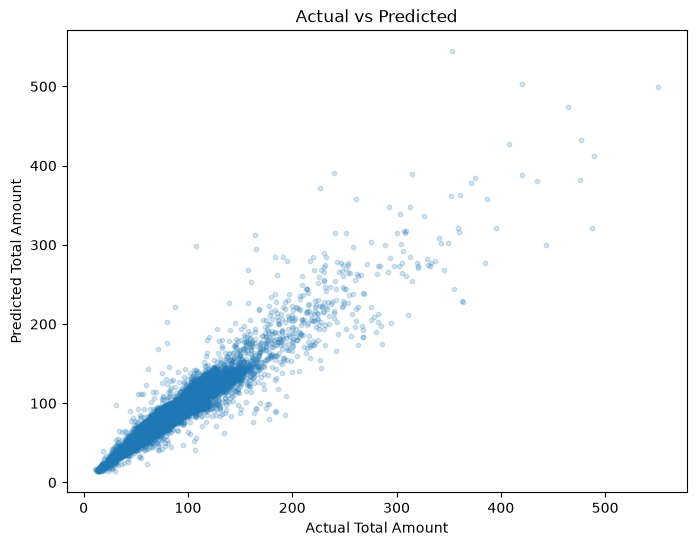

In [945]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_pred,
    alpha=0.2,
    s=10
)

plt.xlabel("Actual Total Amount")
plt.ylabel("Predicted Total Amount")
plt.title("Actual vs Predicted")

plt.show()

In [946]:
residuals = y_test.values - rf_pred

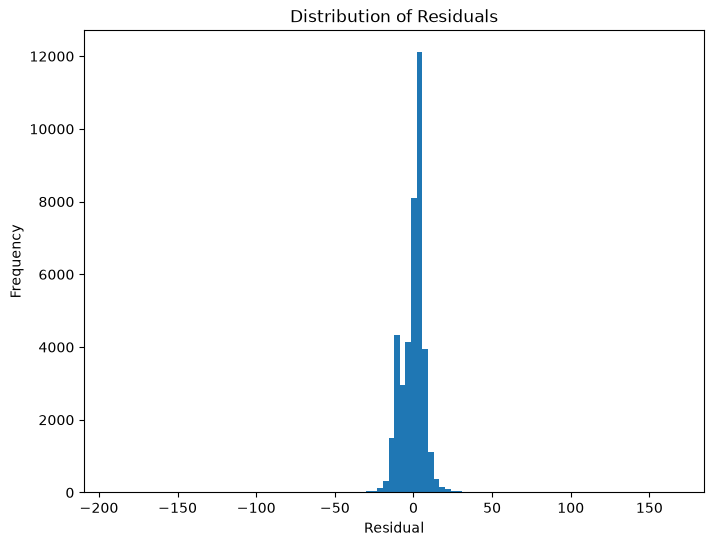

In [947]:
plt.figure(figsize=(8, 6))

plt.hist(
    residuals,
    bins=100
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")

plt.show()

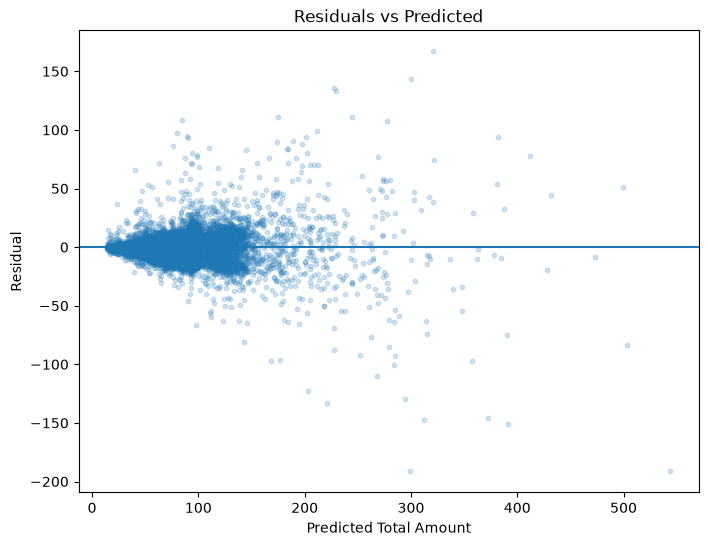

In [948]:
plt.figure(figsize=(8, 6))

plt.scatter(
    rf_pred,
    residuals,
    alpha=0.2,
    s=10
)

plt.axhline(
    y=0
)

plt.xlabel("Predicted Total Amount")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted")

plt.show()

Classification

In [949]:
df_class = df[df["payment_type"] == 1].copy()

In [950]:
df_class["tip_percentage"] = (
    df_class["tip_amount"] /
    df_class["fare_amount"]
) * 100

In [951]:
df_class["high_tip"] = (
    df_class["tip_percentage"] >= 20
).astype(int)

In [952]:
df_class["tip_percentage"] >= 20

12          True
24         False
32          True
55          True
62          True
           ...  
2824359     True
2824387    False
2824394    False
2824402    False
2824432     True
Name: tip_percentage, Length: 170179, dtype: bool

In [953]:
df_class["high_tip"].value_counts()

high_tip
1    124262
0     45917
Name: count, dtype: int64

In [954]:
df_class["high_tip"].value_counts(normalize=True) * 100

high_tip
1    73.01841
0    26.98159
Name: proportion, dtype: float64

In [955]:
df_class["tip_percentage"].describe()

count    1.701790e+05
mean     3.071025e+01
std      3.393785e+03
min      0.000000e+00
25%      1.771429e+01
50%      2.364286e+01
75%      2.826990e+01
max      1.400000e+06
Name: tip_percentage, dtype: float64

In [956]:
df_class["tip_percentage"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

0.50    23.642857
0.75    28.269896
0.90    31.188119
0.95    35.047393
0.99    42.438272
Name: tip_percentage, dtype: float64

In [957]:
print("Above 100%:",
      (df_class["tip_percentage"] > 100).sum())

print("Above 200%:",
      (df_class["tip_percentage"] > 200).sum())

print("Above 500%:",
      (df_class["tip_percentage"] > 500).sum())

Above 100%: 93
Above 200%: 15
Above 500%: 4


In [958]:
df_class.nlargest(
    20,
    "tip_percentage"
)[
    [
        "fare_amount",
        "tip_amount",
        "total_amount",
        "trip_distance",
        "trip_duration_minutes",
        "RatecodeID",
        "tip_percentage"
    ]
]

,fare_amount,tip_amount,total_amount,trip_distance,trip_duration_minutes,RatecodeID,tip_percentage
2157284,0.01,140.00,163.33,12.40,75.783333,5.0,1.400000e+06
492657,0.75,75.00,91.50,8.54,26.816667,5.0,1.000000e+04
1232593,0.08,4.00,12.02,0.10,2.816667,5.0,5.000000e+03
1362936,0.20,4.14,20.72,6.04,24.750000,5.0,2.070000e+03
1530813,18.40,80.00,106.84,5.45,9.583333,1.0,4.347826e+02
845594,20.50,80.00,108.94,4.26,10.983333,1.0,3.902439e+02
1164761,70.00,250.00,330.94,15.38,23.066667,2.0,3.571429e+02
2182515,16.30,55.00,82.24,2.44,15.700000,1.0,3.374233e+02
1076599,47.50,132.00,195.88,5.71,22.050000,3.0,2.778947e+02
1676769,38.00,100.00,156.69,9.20,20.883333,1.0,2.631579e+02


In [959]:
df_class["fare_amount"].quantile(
    [0.001, 0.01, 0.05, 0.50]
)

0.001     7.2
0.010    18.4
0.050    31.0
0.500    54.5
Name: fare_amount, dtype: float64

In [960]:
df_class["pre_tip_amount"] = (
    df_class["total_amount"] -
    df_class["tip_amount"]
)

In [961]:
df_class["pre_tip_amount"].describe()

count    170179.000000
mean         71.900528
std          22.484540
min           8.020000
25%          57.440000
50%          71.090000
75%          82.690000
max         486.100000
Name: pre_tip_amount, dtype: float64

In [962]:
(df_class["pre_tip_amount"] <= 0).sum()

np.int64(0)

In [963]:
df_class = df_class[
    df_class["pre_tip_amount"] > 0
].copy()

In [964]:
df_class["tip_percentage"] = (
    df_class["tip_amount"] /
    df_class["pre_tip_amount"]
) * 100

In [965]:
df_class["tip_percentage"].describe()

count    170179.000000
mean         17.012681
std           7.644621
min           0.000000
25%          14.338973
50%          19.579151
75%          20.003195
max         600.085727
Name: tip_percentage, dtype: float64

In [966]:
df_class["tip_percentage"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
)

0.500    19.579151
0.750    20.003195
0.900    24.464869
0.950    25.000000
0.990    29.997036
0.999    50.000000
Name: tip_percentage, dtype: float64

In [967]:
df_class["high_tip"] = (
    df_class["tip_percentage"] >= 20
).astype(int)

In [968]:
df_class["high_tip"].value_counts()

high_tip
0    104895
1     65284
Name: count, dtype: int64

In [969]:
df_class["high_tip"].value_counts(
    normalize=True
) * 100

high_tip
0    61.63804
1    38.36196
Name: proportion, dtype: float64

In [970]:
class_features = [
    "trip_distance",
    "trip_duration_minutes",
    "passenger_count",
    "pickup_hour",
    "pickup_dayofweek",
    "is_weekend",
    "PULocationID",
    "DOLocationID",
    "RatecodeID",
    "fare_amount"
]

In [971]:
x_class = df_class[class_features]
y_class = df_class["high_tip"]

In [972]:
from sklearn.model_selection import train_test_split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    x_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

In [973]:
print("Training:")
print(y_train_c.value_counts(normalize=True) * 100)

print()

print("Testing:")
print(y_test_c.value_counts(normalize=True) * 100)

Training:
high_tip
0    61.63813
1    38.36187
Name: proportion, dtype: float64

Testing:
high_tip
0    61.637678
1    38.362322
Name: proportion, dtype: float64


In [974]:
print(X_train_c.shape)
print(X_test_c.shape)

(136143, 10)
(34036, 10)


Logistic Regression

In [975]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [976]:
log_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

In [977]:
LogisticRegression(
    max_iter=1000,
    random_state=42
)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [978]:
log_model.fit(
    X_train_c,
    y_train_c
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['trip_distance','trip_duration_minutes','passenger_count',..., 'DOLocationID','RatecodeID','fare_amount']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [979]:
log_pred = log_model.predict(
    X_test_c
)

In [980]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print(
    "Accuracy:",
    accuracy_score(y_test_c, log_pred)
)

print(
    "Precision:",
    precision_score(y_test_c, log_pred)
)

print(
    "Recall:",
    recall_score(y_test_c, log_pred)
)

print(
    "F1:",
    f1_score(y_test_c, log_pred)
)

Accuracy: 0.635914913620872
Precision: 0.5916230366492147
Recall: 0.16443287125679712
F1: 0.2573414838787007


In [981]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test_c,
    log_pred
)

cm

array([[19497,  1482],
       [10910,  2147]])

In [982]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test_c,
        log_pred
    )
)

              precision    recall  f1-score   support

           0       0.64      0.93      0.76     20979
           1       0.59      0.16      0.26     13057

    accuracy                           0.64     34036
   macro avg       0.62      0.55      0.51     34036
weighted avg       0.62      0.64      0.57     34036



In [983]:
log_proba = log_model.predict_proba(X_test_c)[:, 1]

In [984]:
thresholds = [0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:
    pred_threshold = (
        log_proba >= threshold
    ).astype(int)

    print("Threshold:", threshold)
    print("Accuracy:",
          accuracy_score(y_test_c, pred_threshold))
    print("Precision:",
          precision_score(y_test_c, pred_threshold))
    print("Recall:",
          recall_score(y_test_c, pred_threshold))
    print("F1:",
          f1_score(y_test_c, pred_threshold))
    print("----------------------")

Threshold: 0.4
Accuracy: 0.6008637912798214
Precision: 0.48154104321073976
Recall: 0.5274565367235965
F1: 0.5034540736138017
----------------------
Threshold: 0.5
Accuracy: 0.635914913620872
Precision: 0.5916230366492147
Recall: 0.16443287125679712
F1: 0.2573414838787007
----------------------
Threshold: 0.6
Accuracy: 0.6175226231049477
Precision: 0.568904593639576
Recall: 0.012330550662479896
F1: 0.02413793103448276
----------------------
Threshold: 0.7
Accuracy: 0.6163473968738983
Precision: 0.4
Recall: 0.0001531745423910546
F1: 0.0003062318174858368
----------------------


In [985]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

rf_clf.fit(X_train_c, y_train_c)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [986]:
rf_clf_pred = rf_clf.predict(X_test_c)

In [987]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:",
      accuracy_score(y_test_c, rf_clf_pred))

print("Precision:",
      precision_score(y_test_c, rf_clf_pred))

print("Recall:",
      recall_score(y_test_c, rf_clf_pred))

print("F1:",
      f1_score(y_test_c, rf_clf_pred))

Accuracy: 0.6913268304148549
Precision: 0.6219290698785966
Recall: 0.49827678639810064
F1: 0.5532783399948975


In [988]:
from sklearn.metrics import confusion_matrix

confusion_matrix(
    y_test_c,
    rf_clf_pred
)

array([[17024,  3955],
       [ 6551,  6506]])

In [989]:
rf_proba = rf_clf.predict_proba(X_test_c)[:, 1]

In [990]:
thresholds = [0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:
    pred = (rf_proba >= threshold).astype(int)

    print("Threshold:", threshold)
    print("Accuracy:", accuracy_score(y_test_c, pred))
    print("Precision:", precision_score(y_test_c, pred))
    print("Recall:", recall_score(y_test_c, pred))
    print("F1:", f1_score(y_test_c, pred))
    print("----------------")

Threshold: 0.4
Accuracy: 0.6874485838523916
Precision: 0.6034202650705429
Recall: 0.5404763728268361
F1: 0.5702165481577246
----------------
Threshold: 0.5
Accuracy: 0.6913268304148549
Precision: 0.6219290698785966
Recall: 0.49827678639810064
F1: 0.5532783399948975
----------------
Threshold: 0.6
Accuracy: 0.6767834058056176
Precision: 0.6528397264347309
Recall: 0.3362947078195604
F1: 0.44391649395946015
----------------
Threshold: 0.7
Accuracy: 0.6221647667175931
Precision: 0.7100213219616205
Recall: 0.025503561308110594
F1: 0.04923850362265267
----------------


In [991]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(
    y_test_c,
    rf_proba
)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.7029733318697093


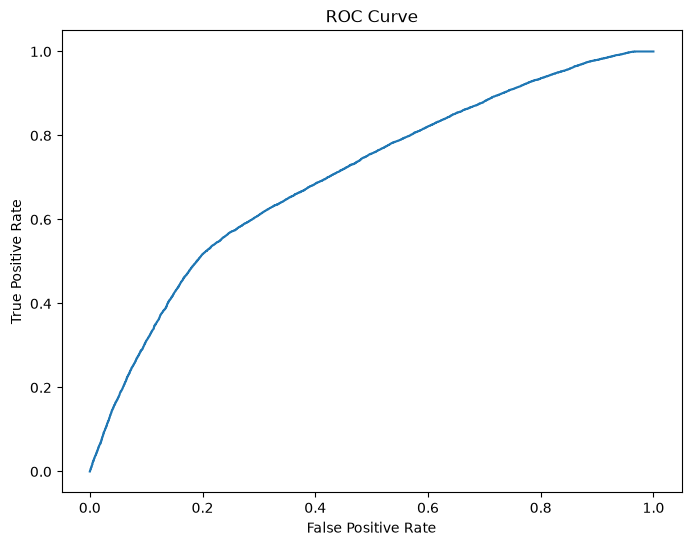

In [992]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_test_c,
    rf_proba
)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.show()

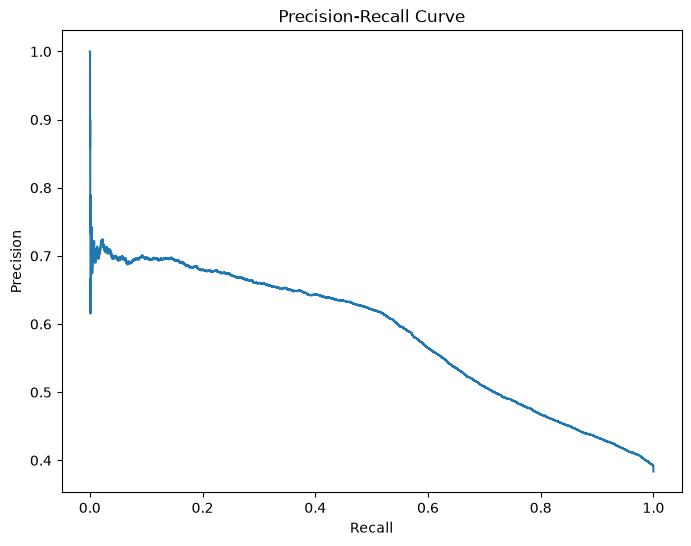

In [993]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds_pr = precision_recall_curve(
    y_test_c,
    rf_proba
)

plt.figure(figsize=(8, 6))

plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")

plt.show()

In [994]:
from sklearn.metrics import average_precision_score

ap = average_precision_score(
    y_test_c,
    rf_proba
)

print("Average Precision:", ap)

Average Precision: 0.5834935197687908


In [995]:
class_importance = pd.DataFrame({
    "Feature": X_train_c.columns,
    "Importance": rf_clf.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

class_importance

,Feature,Importance
6,PULocationID,0.405663
7,DOLocationID,0.157419
8,RatecodeID,0.109211
0,trip_distance,0.090953
2,passenger_count,0.071928
1,trip_duration_minutes,0.061444
9,fare_amount,0.049806
3,pickup_hour,0.033188
4,pickup_dayofweek,0.017025
5,is_weekend,0.003363


In [996]:
X_perm_c = X_test_c.sample(
    n=min(50000, len(X_test_c)),
    random_state=42
)

y_perm_c = y_test_c.loc[X_perm_c.index]

In [997]:
from sklearn.inspection import permutation_importance

perm_c = permutation_importance(
    rf_clf,
    X_perm_c,
    y_perm_c,
    n_repeats=5,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

In [998]:
perm_class_df = pd.DataFrame({
    "Feature": X_perm_c.columns,
    "Importance": perm_c.importances_mean,
    "Std": perm_c.importances_std
}).sort_values(
    by="Importance",
    ascending=False
)

perm_class_df

,Feature,Importance,Std
6,PULocationID,0.095350,0.000969
8,RatecodeID,0.027119,0.001096
0,trip_distance,0.022699,0.002022
2,passenger_count,0.020281,0.001594
7,DOLocationID,0.013564,0.001146
9,fare_amount,0.006443,0.000614
1,trip_duration_minutes,0.005154,0.000657
3,pickup_hour,0.000373,0.000282
4,pickup_dayofweek,0.000038,0.000313
5,is_weekend,-0.000041,0.000116


Clustering

In [999]:
cluster_source = df[
    (df["fare_amount"] > 0) &
    (df["trip_distance"] > 0) &
    (df["trip_duration_minutes"] >= 1) &
    (df["trip_duration_minutes"] <= 120)
].copy()

In [1000]:
cluster_df[
    ["trip_distance", "trip_duration_minutes", "fare_amount"]
].describe()

,trip_distance,trip_duration_minutes,fare_amount
count,200000.000000,200000.000000,200000.000000
mean,3.271697,14.896627,18.298931
std,4.375610,11.694593,17.034289
min,0.010000,1.000000,0.010000
25%,1.000000,7.216667,8.600000
50%,1.690000,11.633333,12.800000
75%,3.110000,18.616667,19.800000
max,97.220000,119.666667,586.100000


In [1001]:
print(
    "Negative fares:",
    (cluster_df["fare_amount"] < 0).sum()
)

print(
    "Zero fares:",
    (cluster_df["fare_amount"] == 0).sum()
)

print(
    "Negative/zero distances:",
    (cluster_df["trip_distance"] <= 0).sum()
)

print(
    "Negative/zero durations:",
    (cluster_df["trip_duration_minutes"] <= 0).sum()
)

Negative fares: 0
Zero fares: 0
Negative/zero distances: 0
Negative/zero durations: 0


In [1002]:
cluster_features = [
    "trip_distance",
    "trip_duration_minutes",
    "fare_amount"
]

In [1003]:
cluster_df = df[
    cluster_features
].sample(
    n=min(200000, len(df)),
    random_state=42
).copy()

In [1004]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_cluster = scaler.fit_transform(
    cluster_df
)

In [1005]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(
    X_cluster
)

In [1006]:
clusters = kmeans.fit_predict(X_cluster)

In [1007]:
cluster_df["cluster"] = clusters

In [1008]:
cluster_df["cluster"].value_counts()

cluster
0    98809
1    97628
2     2165
Name: count, dtype: int64

In [1009]:
cluster_df.groupby("cluster")[cluster_features].mean()

,trip_distance,trip_duration_minutes,fare_amount
cluster,,,
0,18.130642,45.218500,71.299143
1,9.259511,25.828685,40.765640
2,37.398919,61.837983,185.803570


In [1010]:
from sklearn.cluster import KMeans

inertias = []

k_values = range(2, 9)

for k in k_values:
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    km.fit(X_cluster)

    inertias.append(km.inertia_)

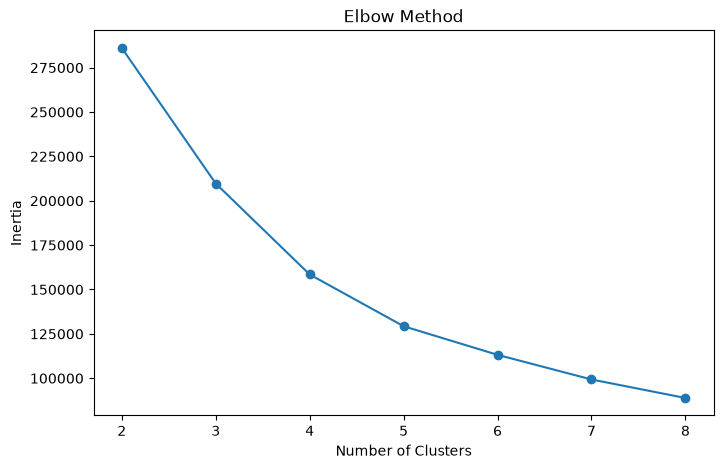

In [1011]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [1012]:
from sklearn.metrics import silhouette_score

silhouette_sample = X_cluster[:30000]

In [1013]:
for k in range(2, 7):

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = km.fit_predict(
        silhouette_sample
    )

    score = silhouette_score(
        silhouette_sample,
        labels
    )

    print(
        "k =", k,
        "Silhouette Score =", score
    )

k = 2 Silhouette Score = 0.5351448238404579
k = 3 Silhouette Score = 0.5469640803207036
k = 4 Silhouette Score = 0.49213489218659645
k = 5 Silhouette Score = 0.4074671312219274
k = 6 Silhouette Score = 0.3810620195876704


In [1014]:
kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

clusters_2 = kmeans_2.fit_predict(X_cluster)

cluster_df["cluster_2"] = clusters_2

In [1015]:
cluster_df.groupby(
    "cluster_2"
)[cluster_features].mean()

,trip_distance,trip_duration_minutes,fare_amount
cluster_2,,,
0,18.649460,45.648355,74.059913
1,9.311658,26.090804,41.020753


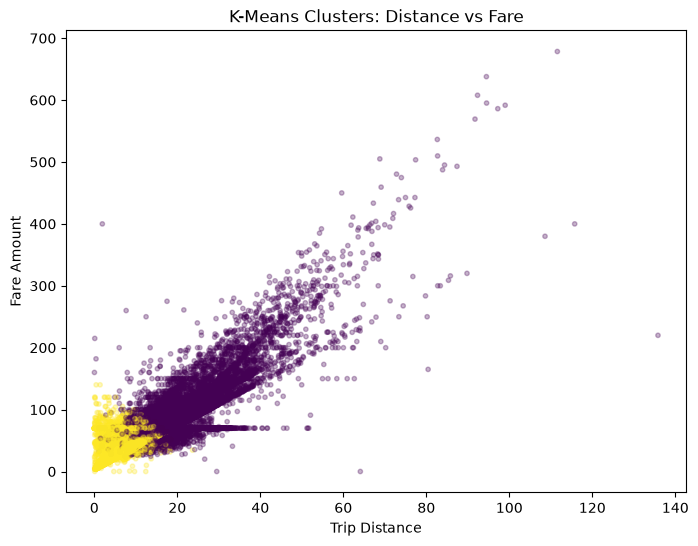

In [1016]:
plt.figure(figsize=(8, 6))

plt.scatter(
    cluster_df["trip_distance"],
    cluster_df["fare_amount"],
    c=cluster_df["cluster_2"],
    alpha=0.3,
    s=10
)

plt.xlabel("Trip Distance")
plt.ylabel("Fare Amount")
plt.title("K-Means Clusters: Distance vs Fare")

plt.show()

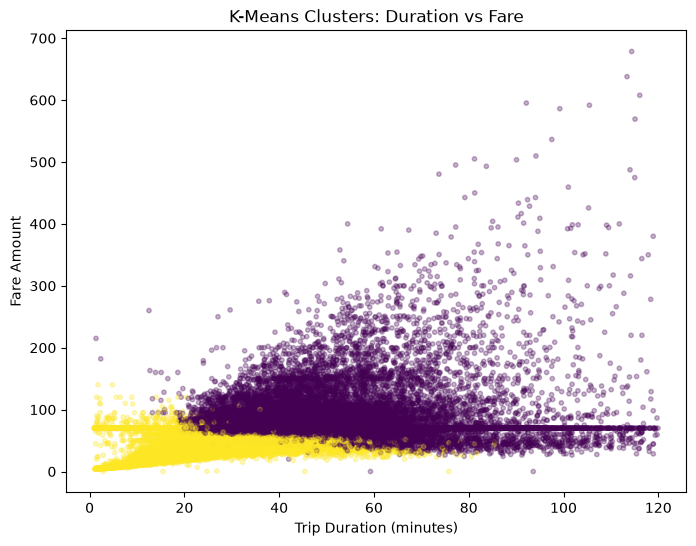

In [1017]:
plt.figure(figsize=(8, 6))

plt.scatter(
    cluster_df["trip_duration_minutes"],
    cluster_df["fare_amount"],
    c=cluster_df["cluster_2"],
    alpha=0.3,
    s=10
)

plt.xlabel("Trip Duration (minutes)")
plt.ylabel("Fare Amount")
plt.title("K-Means Clusters: Duration vs Fare")

plt.show()

In [1018]:
cluster_features = [
    "trip_distance",
    "trip_duration_minutes",
    "fare_amount"
]

cluster_df = cluster_source[
    cluster_features
].sample(
    n=min(200000, len(cluster_source)),
    random_state=42
).copy()

In [1019]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_cluster = scaler.fit_transform(
    cluster_df
)

In [1020]:
from sklearn.cluster import KMeans

kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

cluster_df["cluster_2"] = (
    kmeans_2.fit_predict(X_cluster)
)

In [1021]:
cluster_df.groupby(
    "cluster_2"
)[cluster_features].agg(
    ["count", "mean", "median"]
)

trip_distance                   trip_duration_minutes             \
                  count       mean median                 count       mean   
cluster_2                                                                    
0                 99286  18.649460  18.00                 99286  45.648355   
1                 99316   9.311658   9.44                 99316  26.090804   

                     fare_amount                    
              median       count       mean median  
cluster_2                                           
0          43.583333       99286  74.059913   70.0  
1          25.016667       99316  41.020753   40.8

In [1022]:
kmeans_2.cluster_centers_

array([[ 0.80610953,  0.64243264,  0.70604199],
       [-0.80536304, -0.64183772, -0.70538816]])

In [1023]:
centers_original = scaler.inverse_transform(
    kmeans_2.cluster_centers_
)

centers_df = pd.DataFrame(
    centers_original,
    columns=cluster_features
)

centers_df

,trip_distance,trip_duration_minutes,fare_amount
0,18.651453,45.649152,74.065743
1,9.312580,26.096110,41.025237


PCA

In [1024]:
pca_features = [
    "trip_distance",
    "trip_duration_minutes",
    "fare_amount"
]

In [1025]:
X_pca = cluster_source[pca_features].sample(
    n=min(100000, len(cluster_source)),
    random_state=42
)

In [1026]:
from sklearn.preprocessing import StandardScaler

scalar_pca = StandardScaler()

X_pca_scaled = scalar_pca.fit_transform(X_pca)

In [1027]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=2
)

X_pca_2d = pca.fit_transform(
    X_pca_scaled
)

In [1028]:
pca.explained_variance_ratio_

array([0.79290283, 0.16655666])

In [1029]:
pca.explained_variance_ratio_.sum()

np.float64(0.959459489427148)

In [1030]:
pca.components_

array([[ 0.61184117,  0.51747043,  0.59822632],
       [-0.29740739,  0.85131464, -0.4322178 ]])

In [1031]:
pca_components = pd.DataFrame(
    pca.components_,
    columns=pca_features,
    index=["PC1", "PC2"]
)

pca_components

,trip_distance,trip_duration_minutes,fare_amount
PC1,0.611841,0.517470,0.598226
PC2,-0.297407,0.851315,-0.432218


In [1032]:
pca_df = pd.DataFrame(
    X_pca_2d,
    columns=["PC1", "PC2"]
)

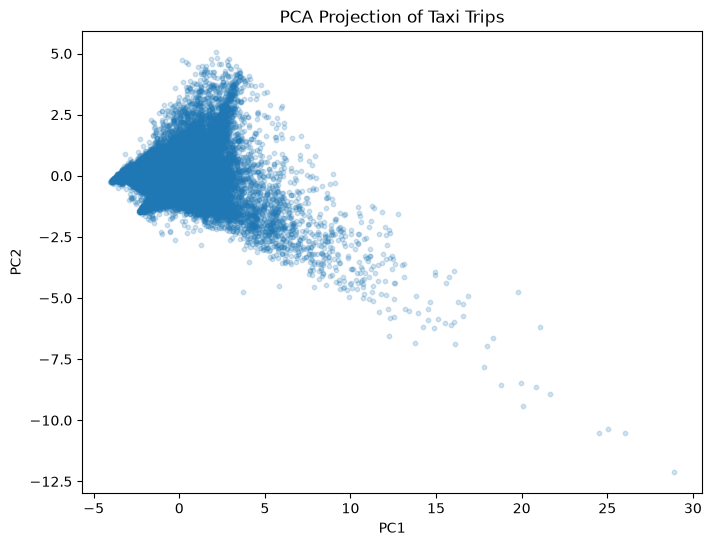

In [1033]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    alpha=0.2,
    s=10
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection of Taxi Trips")

plt.show()

In [1034]:
pca.explained_variance_ratio_

array([0.79290283, 0.16655666])

In [1035]:
pca.explained_variance_ratio_.sum()

np.float64(0.959459489427148)

In [1036]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_vis = cluster_df[cluster_features]

scaler_vis = StandardScaler()
X_vis_scaled = scaler_vis.fit_transform(X_vis)

pca_vis = PCA(n_components=2)
X_vis_pca = pca_vis.fit_transform(X_vis_scaled)

In [1037]:
pca_cluster_df = pd.DataFrame(
    X_vis_pca,
    columns=["PC1", "PC2"]
)

pca_cluster_df["cluster_2"] = cluster_df["cluster_2"].values

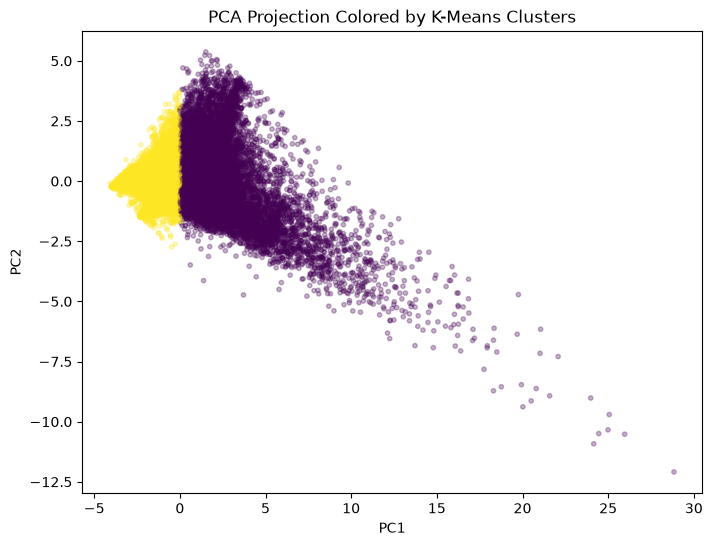

In [1038]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    pca_cluster_df["PC1"],
    pca_cluster_df["PC2"],
    c=pca_cluster_df["cluster_2"],
    alpha=0.3,
    s=10
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection Colored by K-Means Clusters")

plt.show()

Final Findings

In [1039]:
regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "HistGradientBoosting"
    ],
    "MAE": [
        3.27195,
        2.38927,
        2.14240,
        2.14330
    ],
    "RMSE": [
        6.64846,
        5.24313,
        3.96933,
        4.35909
    ],
    "R2": [
        0.90496,
        0.94089,
        0.96612,
        0.95914
    ]
})

regression_results

,Model,MAE,RMSE,R2
0,Linear Regression,3.27195,6.64846,0.90496
1,Decision Tree,2.38927,5.24313,0.94089
2,Random Forest,2.14240,3.96933,0.96612
3,HistGradientBoosting,2.14330,4.35909,0.95914


In [1040]:
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        0.6179,
        0.6401
    ],
    "Precision": [
        0.6116,
        0.6255
    ],
    "Recall": [
        0.9401,
        0.9504
    ],
    "F1": [
        0.7411,
        0.7544
    ]
})

classification_results

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.6179,0.6116,0.9401,0.7411
1,Random Forest,0.6401,0.6255,0.9504,0.7544


In [1041]:
cluster_summary = cluster_df.groupby(
    "cluster_2"
)[
    [
        "trip_distance",
        "trip_duration_minutes",
        "fare_amount"
    ]
].agg(
    ["count", "mean", "median"]
)

cluster_summary

trip_distance                   trip_duration_minutes             \
                  count       mean median                 count       mean   
cluster_2                                                                    
0                 99286  18.649460  18.00                 99286  45.648355   
1                 99316   9.311658   9.44                 99316  26.090804   

                     fare_amount                    
              median       count       mean median  
cluster_2                                           
0          43.583333       99286  74.059913   70.0  
1          25.016667       99316  41.020753   40.8

## Final Findings

### Regression

Random Forest produced the best fare prediction performance:

- MAE ≈ $2.14
- RMSE ≈ $3.97
- R² ≈ 0.966

Trip distance was the most important feature, while RatecodeID
significantly improved predictions for special fare types.

### Classification

Random Forest outperformed Logistic Regression for predicting
high-tip trips.

However, ROC-AUC was only around 0.64, indicating that tipping
behavior cannot be predicted strongly using trip information alone.

### Clustering

K-Means identified two clear trip segments:

1. Short, normal city trips
2. Long, expensive trips

The two-cluster solution achieved a strong silhouette score of
approximately 0.745.

### PCA

PCA reduced three trip features into two principal components
while preserving approximately 98.7% of the variance.

PC1 represented general trip size/cost, while PC2 captured
differences related more strongly to trip duration.

In [1053]:
import joblib

joblib.dump(
    rf_model,
    "nyc_taxi_random_forest.pkl"
)

['nyc_taxi_random_forest.pkl']

In [1054]:
import joblib

loaded_model = joblib.load(
    "nyc_taxi_random_forest.pkl"
)

In [1055]:
features = [
    "trip_distance",
    "trip_duration_minutes",
    "passenger_count",
    "pickup_hour",
    "pickup_dayofweek",
    "is_weekend",
    "PULocationID",
    "DOLocationID",
    "RatecodeID"
]

In [1056]:
new_trip = pd.DataFrame({
    "trip_distance": [5.2],
    "trip_duration_minutes": [22.5],
    "passenger_count": [1],
    "pickup_hour": [18],
    "pickup_dayofweek": [4],
    "is_weekend": [0],
    "PULocationID": [132],
    "DOLocationID": [161],
    "RatecodeID": [1]
})

In [1057]:
prediction = loaded_model.predict(
    new_trip
)

print(prediction)

[44.85673586]


In [1058]:
new_trip = new_trip[features]

In [1059]:
joblib.dump(
    rf_pipeline,
    "nyc_taxi_pipeline.pkl"
)

['nyc_taxi_pipeline.pkl']

In [1060]:
new_data = pd.DataFrame({
    "trip_distance": [5.2],
    "trip_duration_minutes": [22.5],
    "passenger_count": [1],
    "pickup_hour": [18],
    "pickup_dayofweek": [4],
    "is_weekend": [0],
    "PULocationID": [132],
    "DOLocationID": [161],
    "RatecodeID": [1]
})

In [1061]:
pipeline = joblib.load(
    "nyc_taxi_pipeline.pkl"
)

prediction = pipeline.predict(
    new_data
)

In [1062]:
original_pred = rf_model.predict(
    X_test.head(5)
)

joblib.dump(
    rf_model,
    "nyc_taxi_random_forest.pkl"
)

loaded_model = joblib.load(
    "nyc_taxi_random_forest.pkl"
)

loaded_pred = loaded_model.predict(
    X_test.head(5)
)

print(original_pred)
print(loaded_pred)

[59.77285259 63.28393458 64.63999264 94.43147286 59.05364235]
[59.77285259 63.28393458 64.63999264 94.43147286 59.05364235]


In [1063]:
def predict_taxi_fare(
    model,
    trip_distance,
    trip_duration_minutes,
    passenger_count,
    pickup_hour,
    pickup_dayofweek,
    is_weekend,
    PULocationID,
    DOLocationID,
    RatecodeID
):
    new_trip = pd.DataFrame({
        "trip_distance": [trip_distance],
        "trip_duration_minutes": [trip_duration_minutes],
        "passenger_count": [passenger_count],
        "pickup_hour": [pickup_hour],
        "pickup_dayofweek": [pickup_dayofweek],
        "is_weekend": [is_weekend],
        "PULocationID": [PULocationID],
        "DOLocationID": [DOLocationID],
        "RatecodeID": [RatecodeID]
    })

    prediction = model.predict(new_trip)

    return prediction[0]

In [1064]:
fare = predict_taxi_fare(
    loaded_model,
    trip_distance=5.2,
    trip_duration_minutes=22.5,
    passenger_count=1,
    pickup_hour=18,
    pickup_dayofweek=4,
    is_weekend=0,
    PULocationID=132,
    DOLocationID=161,
    RatecodeID=1
)

print("Predicted fare:", round(fare, 2))

Predicted fare: 44.86
